# NIFTY 50 and News — Exploratory Data Analysis

This notebook explores the project's existing processed datasets. It does **not** download data, run FinBERT, or train a model.

**Before running:** open this notebook from the project root folder, `finance-IDC-Project`, and select your `(finance-IDC)` kernel.

It examines:
- NIFTY 50 closing prices and trading volume
- Daily return distribution and volatility
- News volume over time and per trading session
- Sentiment score distribution and daily sentiment
- Sentiment versus next-session return
- Basic data-quality checks


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# This assumes the notebook is running from the project root.
PROJECT_ROOT = Path.cwd()
DATA = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)
print("Processed data folder:", DATA)
print("Folder exists:", DATA.exists())

if not DATA.exists():
    raise FileNotFoundError(
        "Could not find data/processed. Open Jupyter from "
        r"C:\Users\surya\Documents\finance-IDC-Project"
    )


Project root: C:\Users\surya\Documents\finance-IDC-Project
Processed data folder: C:\Users\surya\Documents\finance-IDC-Project\data\processed
Folder exists: True


In [2]:
# Load the processed datasets used by the project.
prices_path = DATA / "nifty50_processed.csv"
model_path = DATA / "model_dataset.csv"
news_daily_path = DATA / "news_market_daily.csv"
sentiment_daily_path = DATA / "news_sentiment_daily.csv"
sentiment_scored_path = DATA / "news_sentiment_scored.csv"

def load_csv_if_present(path):
    if path.exists():
        df = pd.read_csv(path)
        print(f"Loaded {path.name}: {len(df):,} rows × {len(df.columns)} columns")
        return df
    print(f"Not found (some later plots may be skipped): {path.name}")
    return None

prices = load_csv_if_present(prices_path)
model = load_csv_if_present(model_path)
news_daily = load_csv_if_present(news_daily_path)
sentiment_daily = load_csv_if_present(sentiment_daily_path)
sentiment_scored = load_csv_if_present(sentiment_scored_path)

display(model.head() if model is not None else prices.head())


Loaded nifty50_processed.csv: 1,437 rows × 14 columns
Loaded model_dataset.csv: 1,437 rows × 18 columns
Loaded news_market_daily.csv: 1,437 rows × 13 columns
Loaded news_sentiment_daily.csv: 1,429 rows × 7 columns
Loaded news_sentiment_scored.csv: 17,629 rows × 12 columns


,date,open,high,low,close,volume,adj_close,daily_return,daily_return_pct,article_count,unique_sources,target_next_session_return_pct,target_next_session_date,mean_sentiment,median_sentiment,positive_fraction,negative_fraction,neutral_fraction
0,2021-01-01,13996.099609,14049.849609,13991.349609,14018.500000,358100.0,14018.500000,NaN,NaN,3,3,0.816067,2021-01-04,0.067812,0.015409,0.000000,0.000000,1.000000
1,2021-01-04,14104.349609,14147.950195,13953.750000,14132.900391,495000.0,14132.900391,0.008161,0.816067,7,7,0.471238,2021-01-05,-0.089613,0.009164,0.142857,0.285714,0.571429
2,2021-01-05,14075.150391,14215.599609,14048.150391,14199.500000,492500.0,14199.500000,0.004712,0.471238,7,5,-0.375013,2021-01-06,0.073094,0.023649,0.142857,0.142857,0.714286
3,2021-01-06,14240.950195,14244.150391,14039.900391,14146.250000,632300.0,14146.250000,-0.003750,-0.375013,4,3,-0.062917,2021-01-07,-0.067827,0.082800,0.250000,0.250000,0.500000
4,2021-01-07,14253.750000,14256.250000,14123.099609,14137.349609,559200.0,14137.349609,-0.000629,-0.062917,5,4,1.484722,2021-01-08,-0.341760,0.012431,0.000000,0.400000,0.600000


In [3]:
# Standardize date columns and inspect the available columns.
def standardize_date(df, candidates=("date", "Date", "datetime", "timestamp")):
    if df is None:
        return None
    df = df.copy()
    for col in candidates:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce", utc=True).dt.tz_convert(None)
            if col != "date":
                df = df.rename(columns={col: "date"})
            break
    return df

prices = standardize_date(prices)
model = standardize_date(model)
news_daily = standardize_date(news_daily)
sentiment_daily = standardize_date(sentiment_daily)
sentiment_scored = standardize_date(sentiment_scored)

for name, df in [
    ("prices", prices), ("model", model), ("news_daily", news_daily),
    ("sentiment_daily", sentiment_daily), ("sentiment_scored", sentiment_scored)
]:
    if df is not None:
        print(f"\n{name}:")
        print(df.columns.tolist())



prices:
['date', 'Adj_Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Daily_Return_Pct', 'Daily_Range', 'Intraday_Change_Pct', 'Year', 'Month', 'Year_Month']

model:
['date', 'open', 'high', 'low', 'close', 'volume', 'adj_close', 'daily_return', 'daily_return_pct', 'article_count', 'unique_sources', 'target_next_session_return_pct', 'target_next_session_date', 'mean_sentiment', 'median_sentiment', 'positive_fraction', 'negative_fraction', 'neutral_fraction']

news_daily:
['date', 'open', 'high', 'low', 'close', 'volume', 'adj_close', 'daily_return', 'daily_return_pct', 'article_count', 'unique_sources', 'target_next_session_return_pct', 'target_next_session_date']

sentiment_daily:
['date', 'article_count', 'mean_sentiment', 'median_sentiment', 'positive_fraction', 'negative_fraction', 'neutral_fraction']

sentiment_scored:
['id', 'title', 'published_at', 'source', 'url', 'published_at_ist', 'feature_date', 'sentiment_positive', 'sentiment_negative', 'sentiment_neut

## 1. NIFTY 50 price history

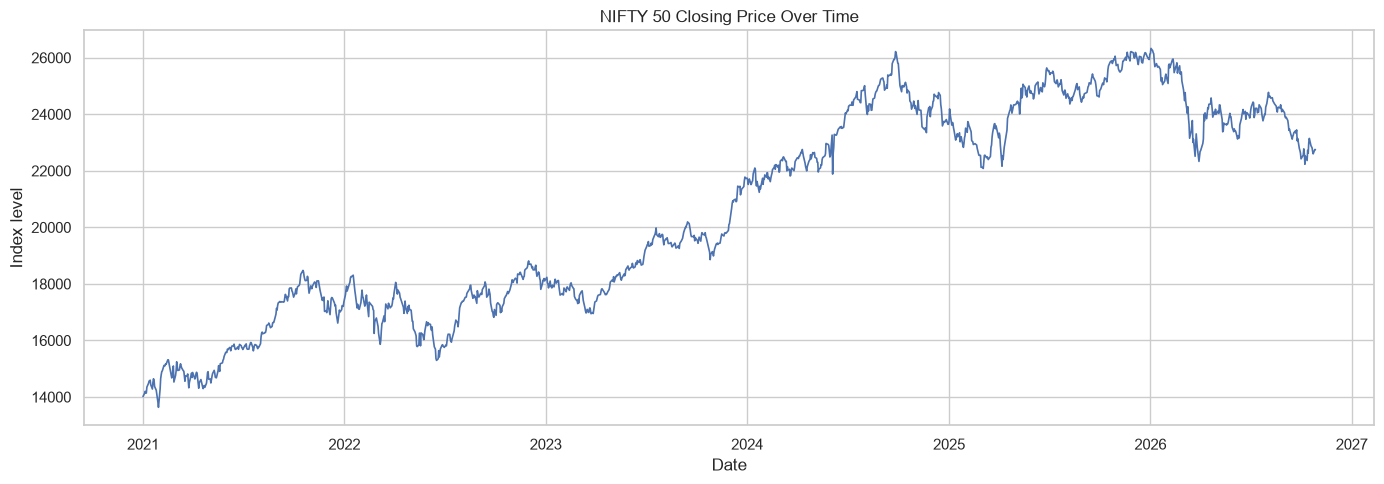

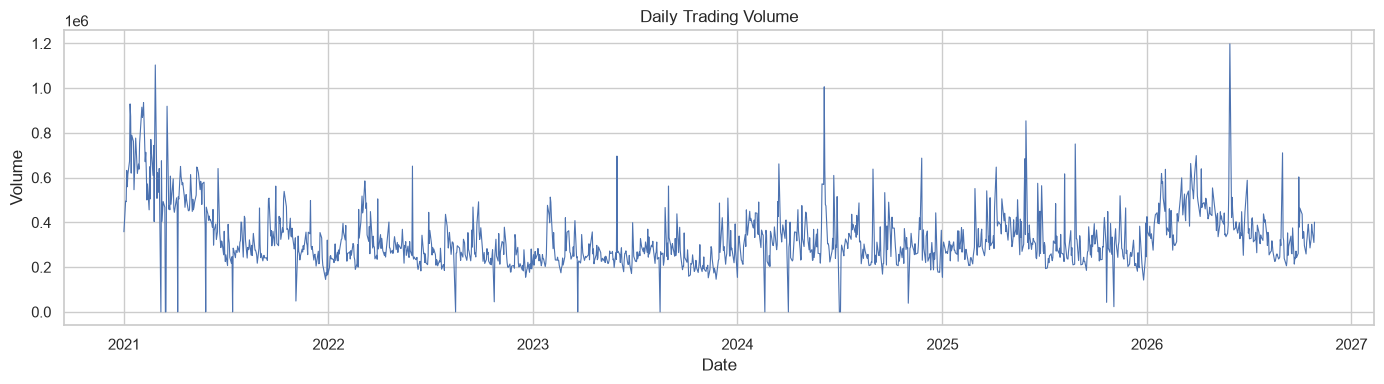

In [4]:
# Use the processed price file if available, otherwise use model_dataset.
price_df = prices if prices is not None else model
if price_df is None:
    raise FileNotFoundError("Neither nifty50_processed.csv nor model_dataset.csv was found.")

# Accommodate the column naming used in this project.
def find_col(df, choices):
    for col in choices:
        if col in df.columns:
            return col
    return None

close_col = find_col(price_df, ["Close", "close", "Adj Close", "adj_close"])
volume_col = find_col(price_df, ["Volume", "volume"])
return_col = find_col(price_df, ["Daily_Return_Pct", "daily_return_pct", "daily_return"])

if close_col is None:
    raise KeyError("Could not find a closing-price column. Check the printed columns above.")

price_df = price_df.dropna(subset=["date"]).sort_values("date")
price_df[close_col] = pd.to_numeric(price_df[close_col], errors="coerce")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(price_df["date"], price_df[close_col], linewidth=1.2)
ax.set(title="NIFTY 50 Closing Price Over Time", xlabel="Date", ylabel="Index level")
plt.tight_layout()
plt.show()

if volume_col:
    price_df[volume_col] = pd.to_numeric(price_df[volume_col], errors="coerce")
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(price_df["date"], price_df[volume_col], linewidth=0.8)
    ax.set(title="Daily Trading Volume", xlabel="Date", ylabel="Volume")
    plt.tight_layout()
    plt.show()
else:
    print("No volume column found in this file.")


## 2. Daily returns: distribution and volatility

,daily_return_pct
count,1436.000000
mean,0.037678
std,0.888962
min,-5.929360
25%,-0.426011
50%,0.042023
75%,0.550525
max,4.742351


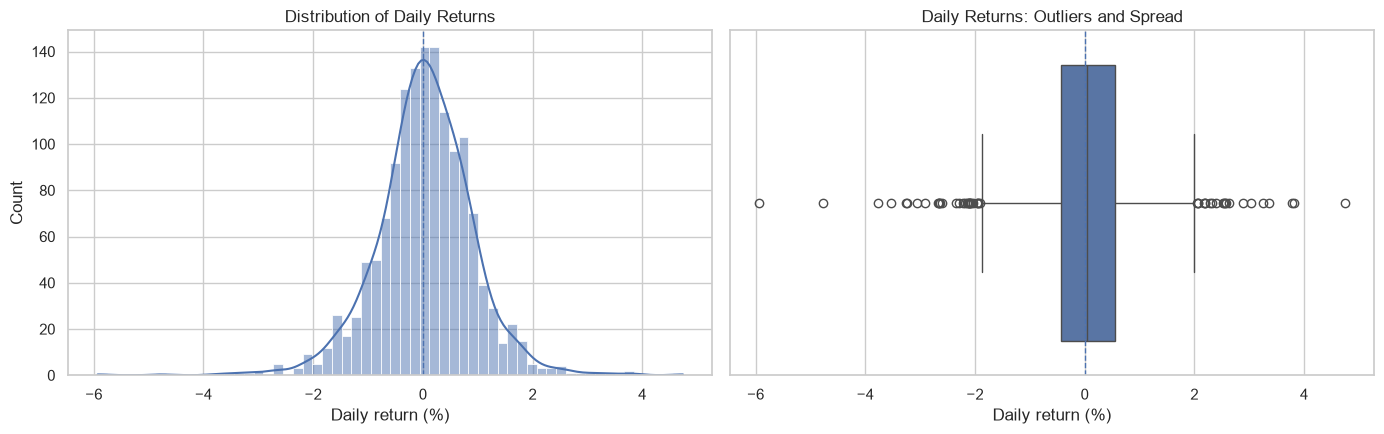

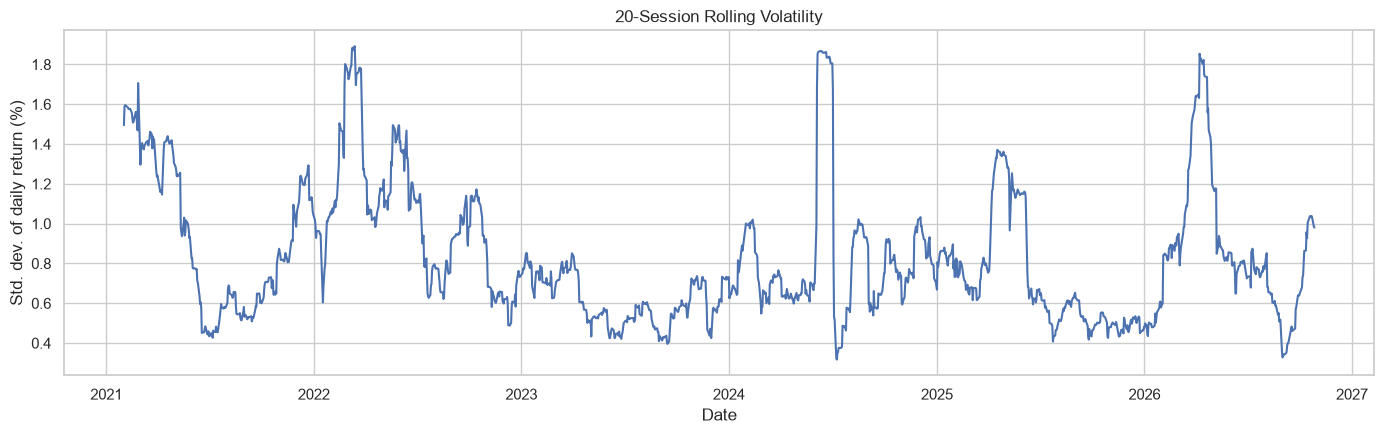

In [5]:
# Calculate returns from close prices if no return column is present.
if return_col is None:
    price_df["return_pct_for_eda"] = price_df[close_col].pct_change() * 100
    return_col = "return_pct_for_eda"
else:
    price_df[return_col] = pd.to_numeric(price_df[return_col], errors="coerce")
    # Daily_Return_Pct is already expressed in percent in this project.

returns = price_df[return_col].replace([np.inf, -np.inf], np.nan).dropna()

display(returns.describe().to_frame("daily_return_pct"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(returns, bins=60, kde=True, ax=axes[0])
axes[0].axvline(0, linestyle="--", linewidth=1)
axes[0].set(title="Distribution of Daily Returns", xlabel="Daily return (%)")

sns.boxplot(x=returns, ax=axes[1])
axes[1].axvline(0, linestyle="--", linewidth=1)
axes[1].set(title="Daily Returns: Outliers and Spread", xlabel="Daily return (%)")
plt.tight_layout()
plt.show()

# Rolling volatility is the standard deviation of the last 20 daily returns.
price_df["rolling_volatility_20"] = price_df[return_col].rolling(20).std()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(price_df["date"], price_df["rolling_volatility_20"])
ax.set(title="20-Session Rolling Volatility", xlabel="Date", ylabel="Std. dev. of daily return (%)")
plt.tight_layout()
plt.show()


## 3. News volume over time

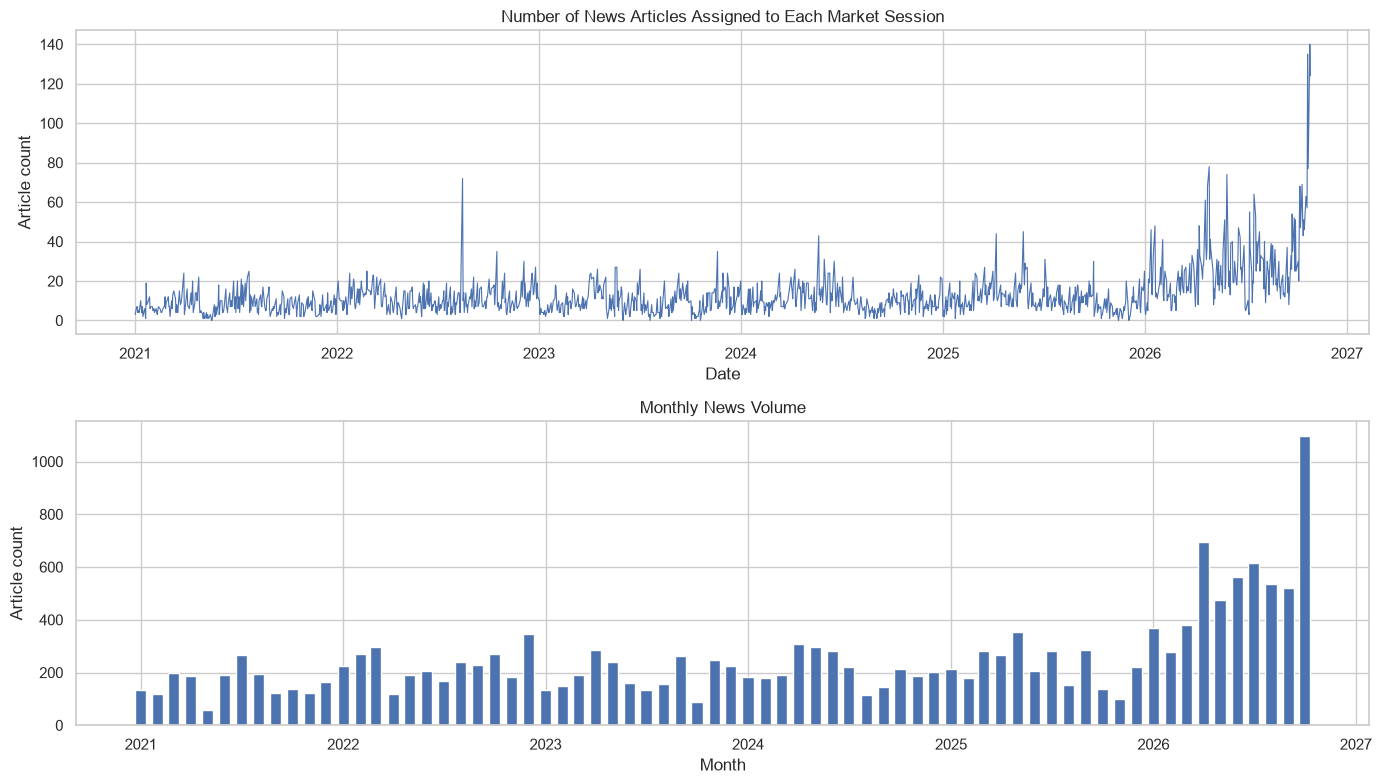

News volume summary:


,articles_per_session
count,1437.000000
mean,12.267919
std,11.308902
min,0.000000
25%,6.000000
50%,10.000000
75%,15.000000
max,140.000000


In [6]:
# Prefer the daily alignment file; fall back to the model dataset.
news_df = news_daily if news_daily is not None else model

if news_df is not None:
    count_col = find_col(news_df, ["article_count", "Article_Count", "news_count", "count"])
    if count_col:
        news_df[count_col] = pd.to_numeric(news_df[count_col], errors="coerce")
        news_df = news_df.dropna(subset=["date"]).sort_values("date")

        fig, axes = plt.subplots(2, 1, figsize=(14, 8))
        axes[0].plot(news_df["date"], news_df[count_col], linewidth=0.8)
        axes[0].set(title="Number of News Articles Assigned to Each Market Session",
                    xlabel="Date", ylabel="Article count")

        monthly = news_df.set_index("date")[count_col].resample("MS").sum()
        axes[1].bar(monthly.index, monthly.values, width=20)
        axes[1].set(title="Monthly News Volume", xlabel="Month", ylabel="Article count")
        plt.tight_layout()
        plt.show()

        print("News volume summary:")
        display(news_df[count_col].describe().to_frame("articles_per_session"))
    else:
        print("No article-count column found in the daily news/model data.")
else:
    print("No daily news or model dataset available.")


## 4. Sentiment score and sentiment over time

Columns in scored-news file: ['id', 'title', 'published_at', 'source', 'url', 'published_at_ist', 'feature_date', 'sentiment_positive', 'sentiment_negative', 'sentiment_neutral', 'sentiment_score', 'sentiment_label']


,sentiment_score
count,17629.000000
mean,0.019438
std,0.508055
min,-0.966996
25%,-0.114884
50%,0.035047
75%,0.230757
max,0.941984


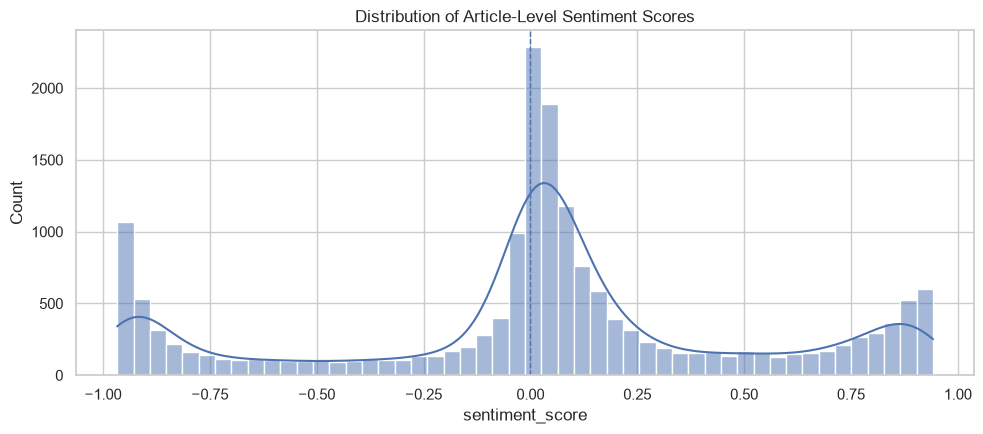

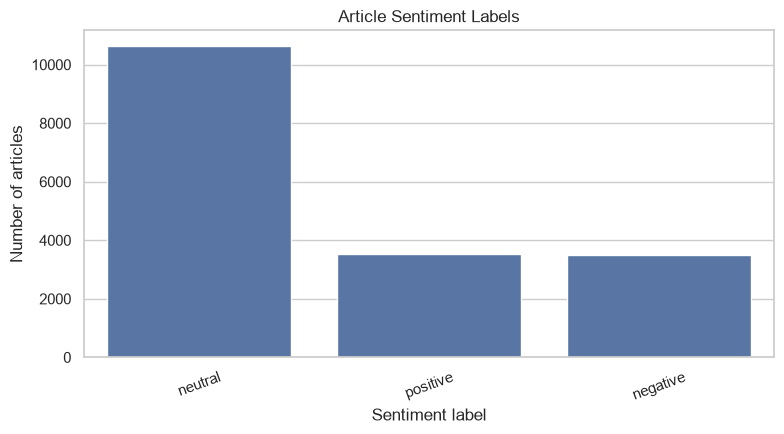

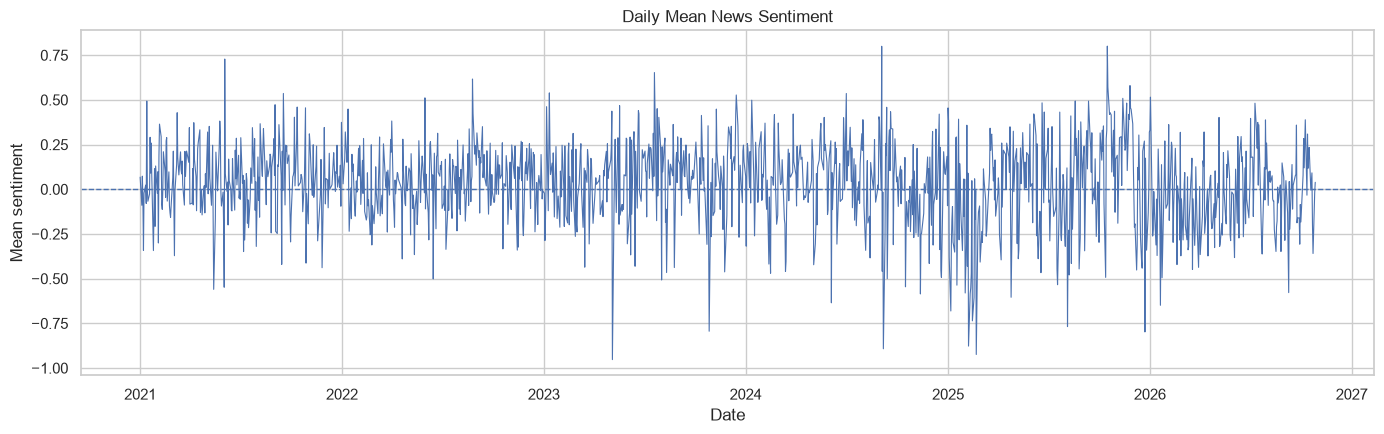

In [7]:
if sentiment_scored is not None:
    print("Columns in scored-news file:", sentiment_scored.columns.tolist())
    # Common score columns used by sentiment-analysis exports.
    score_col = find_col(sentiment_scored, [
        "sentiment_score", "score", "mean_sentiment", "sentiment"
    ])
    label_col = find_col(sentiment_scored, [
        "sentiment_label", "label", "predicted_label"
    ])

    if score_col:
        sentiment_scored[score_col] = pd.to_numeric(sentiment_scored[score_col], errors="coerce")
        scores = sentiment_scored[score_col].dropna()
        display(scores.describe().to_frame("sentiment_score"))
        fig, ax = plt.subplots(figsize=(10, 4.5))
        sns.histplot(scores, bins=50, kde=True, ax=ax)
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set(title="Distribution of Article-Level Sentiment Scores", xlabel=score_col)
        plt.tight_layout()
        plt.show()
    else:
        print("No obvious numeric sentiment score column found; inspect the column list above.")

    if label_col:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        order = sentiment_scored[label_col].value_counts().index
        sns.countplot(data=sentiment_scored, x=label_col, order=order, ax=ax)
        ax.set(title="Article Sentiment Labels", xlabel="Sentiment label", ylabel="Number of articles")
        ax.tick_params(axis="x", rotation=20)
        plt.tight_layout()
        plt.show()
else:
    print("Article-level sentiment file not found; skipping article-level plots.")

# Plot daily mean sentiment if available.
daily_sent_df = sentiment_daily if sentiment_daily is not None else model
if daily_sent_df is not None:
    mean_sent_col = find_col(daily_sent_df, ["mean_sentiment", "Mean_Sentiment"])
    if mean_sent_col:
        daily_sent_df[mean_sent_col] = pd.to_numeric(daily_sent_df[mean_sent_col], errors="coerce")
        daily_sent_df = daily_sent_df.dropna(subset=["date"]).sort_values("date")
        fig, ax = plt.subplots(figsize=(14, 4.5))
        ax.plot(daily_sent_df["date"], daily_sent_df[mean_sent_col], linewidth=0.8)
        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set(title="Daily Mean News Sentiment", xlabel="Date", ylabel="Mean sentiment")
        plt.tight_layout()
        plt.show()
    else:
        print("No mean_sentiment column found for daily sentiment plot.")


## 5. Sentiment versus next-session market return

RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

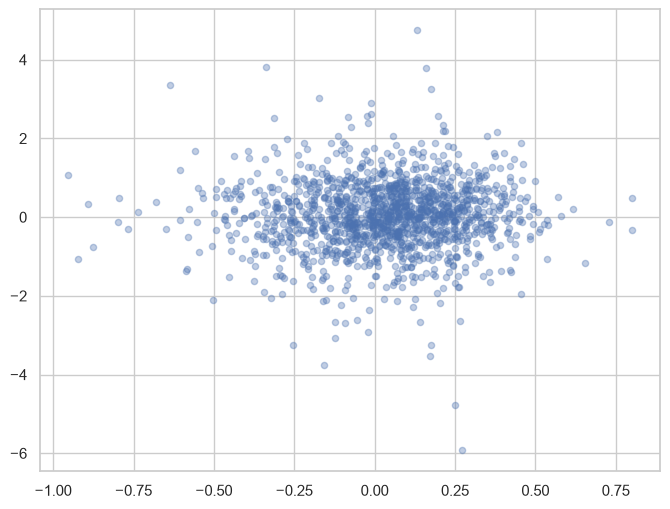

In [8]:
if model is not None:
    x_col = find_col(model, ["mean_sentiment"])
    y_col = find_col(model, ["target_next_session_return_pct"])

    if x_col and y_col:
        plot_df = model[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.regplot(
            data=plot_df, x=x_col, y=y_col, lowess=True,
            scatter_kws={"alpha": 0.35, "s": 20},
            line_kws={"linewidth": 2}, ax=ax
        )
        ax.axhline(0, linestyle="--", linewidth=1)
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set(title="Daily News Sentiment vs Next-Session NIFTY Return",
               xlabel="Mean news sentiment", ylabel="Next-session return (%)")
        plt.tight_layout()
        plt.show()

        print("Correlation (Pearson):", round(plot_df[x_col].corr(plot_df[y_col], method="pearson"), 4))
        print("Correlation (Spearman):", round(plot_df[x_col].corr(plot_df[y_col], method="spearman"), 4))
        print("Number of sessions plotted:", len(plot_df))
    else:
        print("Required columns not found. Expected mean_sentiment and target_next_session_return_pct.")
else:
    print("model_dataset.csv not found; skipping relationship plot.")


## 6. Compare returns on positive-, neutral-, and negative-sentiment sessions

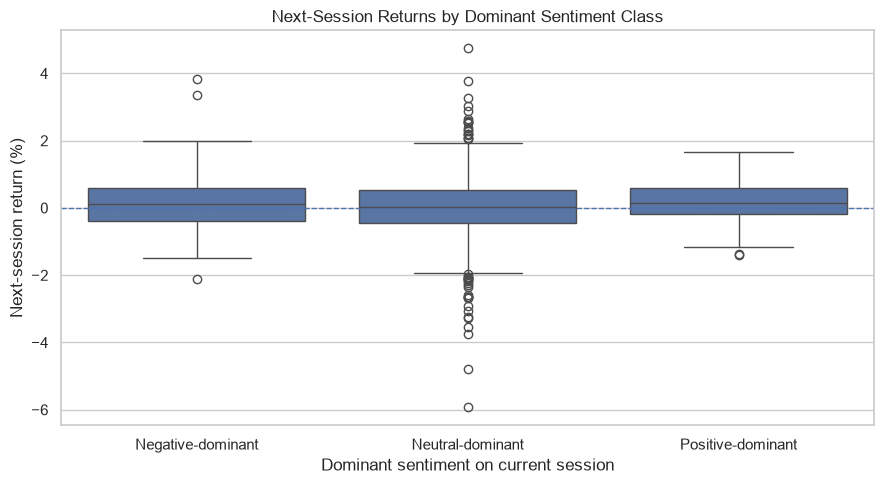

,count,mean,median,std
dominant_sentiment,,,,
Negative-dominant,106,0.132662,0.121973,0.871405
Neutral-dominant,1245,0.019059,0.030619,0.901139
Positive-dominant,77,0.202166,0.148048,0.670704


In [9]:
if model is not None:
    target_col = find_col(model, ["target_next_session_return_pct"])
    positive_col = find_col(model, ["positive_fraction"])
    negative_col = find_col(model, ["negative_fraction"])

    if target_col and positive_col and negative_col:
        tmp = model[[target_col, positive_col, negative_col]].copy()
        tmp = tmp.apply(pd.to_numeric, errors="coerce").dropna()

        # Assign the dominant daily sentiment class, rather than treating it as a causal category.
        tmp["dominant_sentiment"] = np.select(
            [
                (tmp[positive_col] > tmp[negative_col]) &
                (tmp[positive_col] > (1 - tmp[positive_col] - tmp[negative_col])),
                (tmp[negative_col] > tmp[positive_col]) &
                (tmp[negative_col] > (1 - tmp[positive_col] - tmp[negative_col]))
            ],
            ["Positive-dominant", "Negative-dominant"],
            default="Neutral-dominant"
        )

        order = ["Negative-dominant", "Neutral-dominant", "Positive-dominant"]
        fig, ax = plt.subplots(figsize=(9, 5))
        sns.boxplot(data=tmp, x="dominant_sentiment", y=target_col, order=order, ax=ax)
        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set(title="Next-Session Returns by Dominant Sentiment Class",
               xlabel="Dominant sentiment on current session", ylabel="Next-session return (%)")
        plt.tight_layout()
        plt.show()

        display(tmp.groupby("dominant_sentiment")[target_col].agg(
            ["count", "mean", "median", "std"]
        ).reindex(order))
    else:
        print("Required sentiment fractions or target return columns not found.")


## 7. Data quality checks

In [10]:
print("=== Price data ===")
if prices is not None:
    print("Rows:", len(prices))
    print("Duplicate dates:", prices["date"].duplicated().sum() if "date" in prices else "date column missing")
    print("Missing values by column:")
    display(prices.isna().sum().to_frame("missing_count"))
    if "date" in prices:
        print("Date range:", prices["date"].min(), "to", prices["date"].max())

print("\n=== Model dataset ===")
if model is not None:
    print("Rows:", len(model))
    print("Duplicate dates:", model["date"].duplicated().sum() if "date" in model else "date column missing")
    print("Missing values by column:")
    display(model.isna().sum().to_frame("missing_count"))
    if "date" in model:
        print("Date range:", model["date"].min(), "to", model["date"].max())

print("\n=== Notes ===")
print("- Correlation is association, not evidence that sentiment causes market moves.")
print("- A plot of the full dataset is exploratory; forecasting performance must be judged on future/held-out data.")
print("- News timing and assignment to trading sessions can create look-ahead leakage if handled incorrectly.")
print("- Financial returns are noisy; inspect outliers rather than automatically deleting them.")


=== Price data ===
Rows: 1437
Duplicate dates: 0
Missing values by column:


,missing_count
date,0
Adj_Close,0
Close,0
High,0
Low,0
Open,0
Volume,0
Daily_Return,1
Daily_Return_Pct,1
Daily_Range,0


Date range: 2021-01-01 00:00:00 to 2026-10-27 00:00:00

=== Model dataset ===
Rows: 1437
Duplicate dates: 0
Missing values by column:


,missing_count
date,0
open,0
high,0
low,0
close,0
volume,0
adj_close,0
daily_return,1
daily_return_pct,1
article_count,0


Date range: 2021-01-01 00:00:00 to 2026-10-27 00:00:00

=== Notes ===
- Correlation is association, not evidence that sentiment causes market moves.
- A plot of the full dataset is exploratory; forecasting performance must be judged on future/held-out data.
- News timing and assignment to trading sessions can create look-ahead leakage if handled incorrectly.
- Financial returns are noisy; inspect outliers rather than automatically deleting them.
